# Figure 3: Carbon intensity as a function of assumed lifespan

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.patheffects import withStroke


In [32]:
# Load data
df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Carbon Intensity",
)

In [33]:
# ---
# Materials carbon intensity
# ---

# Technology columns
tech_cols = [
    "Bioenergy",
    "Coal",
    "Geothermal",
    "Hydro",
    "Natural Gas",
    "Nuclear",
    "Oil",
    "Solar PV",
    "Wind Onshore",
    "Wind Offshore",
]

# Aggregate by material group and convert to tCO2/MW
df_grouped = (
    df.groupby("Group")[tech_cols]
    .sum()
    / 1000
)

df_grouped = df_grouped.rename(
    columns={
        "Hydro": "Hydropower",
    }
)

# Transpose for plotting
df_plot = df_grouped.T

# Technology order
order = [
    "Bioenergy",
    "Coal",
    "Geothermal",
    "Hydropower",
    "Natural Gas",
    "Nuclear",
    "Oil",
    "Solar PV",
    "Wind Onshore",
    "Wind Offshore",
]

df_plot = df_plot.reindex(order)

# Replace missing values with zero
df_plot = df_plot.fillna(0)


In [34]:

# ---
# Style
# ---

# Minimum font size: 12 pt
FONT_BASE = 12.0
FONT_TICKS = 12.0
FONT_TECH = 12.0
FONT_GROUP = 13.0
FONT_SCENARIO = 12.0
FONT_TOTAL = 12.0
FONT_MANUFACTURING_LABEL = 12.0
FONT_AXIS_LABEL = 13.5
FONT_LEGEND = 12.0
FONT_PANEL_LABEL = 13.0
FONT_VALUE = 12.0    # in-panel readouts
FONT_TITLE = 12.5    # small-multiple titles

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.70,
        "axes.labelsize": FONT_AXIS_LABEL,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TECH,
        "legend.fontsize": FONT_LEGEND,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)

COLOR_BACKGROUND = "white"
COLOR_TEXT = "#1A1A1A"
COLOR_SECONDARY_TEXT = "#4A4A4A"
COLOR_AXIS = "#4A4A4A"
COLOR_GRID = "#C9C9C9"
COLOR_GROUP_LINE = "#8A8A8A"

COLOR_CURVE = "#A9C8DB"      # intensity-vs-lifespan relationship (backdrop)
COLOR_HURDLE = "#C1D8E3"     # threshold hurdle bar, panel b
COLOR_TECH_RANGE = "#DEDBD5" # technical lifespan range
COLOR_RETIRED = "#D2703A"    # retired lifespan
COLOR_KM = "#1D5A7A"         # Kaplan-Meier lifespan
COLOR_FUEL = "#B04E33"       # fuel floor: deeper brick

def halo(linewidth=2.4, foreground="white"):
    return [withStroke(linewidth=linewidth, foreground=foreground)]

In [35]:
# ---
# Configuration
# ---

technology_col = "Technology"
CARBON_THRESHOLD = 25.0  # gCO2/kWh


# ---
# Technology groups - panel a
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}


In [36]:
# ---
# Prepare input
# ---

df_capacity = df_plot.copy()

if technology_col in df_capacity.columns:
    df_capacity = df_capacity.set_index(
        technology_col,
    )

# Harmonise naming
df_capacity = df_capacity.rename(
    index={
        "Hydro": "Hydropower",
    }
)

# Aggregate duplicate technologies if required
df_capacity = (
    df_capacity
    .groupby(df_capacity.index)
    .sum(numeric_only=True)
)


# ---
# Full technology set
# ---

all_techs = [
    tech
    for group in tech_groups.values()
    for tech in group
]

df_capacity = df_capacity.reindex(
    all_techs,
)

# Total manufacturing footprint in tCO2e/MW installed
capacity_input = df_capacity.sum(
    axis=1,
)


# ---
# Fuel footprint
# ---

# Fuel footprint in gCO2e/kWh electricity
fuel_footprint = {
    "Bioenergy": 12 / 0.38,
    "Coal": 317 / 0.44,
    "Geothermal": 0,
    "Hydropower": 0,
    "Natural Gas": 182 / 0.55,
    "Nuclear": 3,
    "Oil": 267 / 0.32,
    "Solar PV": 0,
    "Wind Onshore": 0,
    "Wind Offshore": 0,
}

fuel_series = (
    pd.Series(fuel_footprint)
    .reindex(all_techs)
    .fillna(0)
)


# ---
# Capacity factors
# ---

# Use typical / mean capacity factors for all panel-a scenarios.
capacity_factor_dict = {
    "Bioenergy": 0.636,
    "Coal": 0.600,
    "Geothermal": 0.838,
    "Hydropower": 0.451,
    "Natural Gas": 0.633,
    "Nuclear": 0.817,
    "Oil": 0.263,
    "Solar PV": 0.200,
    "Wind Onshore": 0.338,
    "Wind Offshore": 0.421,
}

cf_mean = pd.Series(capacity_factor_dict).reindex(all_techs)


# ---
# Lifespans from Figure 3
# ---

# Retired observed central estimate
retired_observed = {
    "Bioenergy": 17,
    "Coal": 56,
    "Geothermal": 23,
    "Hydropower": 86,
    "Natural Gas": 44,
    "Nuclear": 31,
    "Oil": 41,
    "Solar PV": 8,
    "Wind Offshore": 22,
    "Wind Onshore": 15,
}

# Technical lifespan bounds from Figure 3
technical_range = {
    "Bioenergy": (20, 45),
    "Coal": (20, 50),
    "Geothermal": (20, 100),
    "Hydropower": (30, 100),
    "Natural Gas": (30, 50),
    "Nuclear": (30, 80),
    "Oil": (20, 50),
    "Solar PV": (20, 35),
    "Wind Offshore": (25, 30),
    "Wind Onshore": (20, 40),
}

# KM summary from Figure 3.
# Priority for panel-a central value: mean > median > lower.
km_summary = {
    "Bioenergy": {"lower": 29, "median": 68, "upper": np.nan},
    "Coal": {"lower": 52, "median": 61, "upper": np.nan},
    "Geothermal": {"lower": 23, "median": np.nan, "upper": np.nan},
    "Hydropower": {"lower": 117, "median": np.nan, "upper": np.nan},
    "Natural Gas": {"lower": 45, "median": 62, "upper": np.nan},
    "Nuclear": {"lower": 30, "median": 45, "upper": np.nan},
    "Oil": {"lower": 37, "median": 58, "upper": np.nan},
    "Solar PV": {"lower": 27, "median": 29, "upper": np.nan},
    "Wind Offshore": {"lower": 22, "median": 24, "upper": np.nan},
    "Wind Onshore": {"lower": 32, "median": 36, "upper": np.nan},
}


def get_km_preferred_value(summary_dict):
    if "mean" in summary_dict and np.isfinite(summary_dict["mean"]):
        return summary_dict["mean"]

    if "median" in summary_dict and np.isfinite(summary_dict["median"]):
        return summary_dict["median"]

    if "lower" in summary_dict and np.isfinite(summary_dict["lower"]):
        return summary_dict["lower"]

    return np.nan


life_retired = pd.Series(retired_observed).reindex(all_techs)
life_km = pd.Series(
    {
        tech: get_km_preferred_value(values)
        for tech, values in km_summary.items()
    }
).reindex(all_techs)
life_technical_mid = pd.Series(
    {
        tech: (bounds[0] + bounds[1]) / 2
        for tech, bounds in technical_range.items()
    }
).reindex(all_techs)


In [37]:
# ---
# Panel a - manufacturing intensity
# ---

# gCO2e/kWh =
# 1000 * tCO2e/MW / (CF * 8760 * lifespan)

def manufacturing_intensity_from_life(life_series):
    conversion_factor = 1000 / (
        cf_mean
        * 8760
        * life_series
    )

    return capacity_input * conversion_factor


manufacturing_retired = manufacturing_intensity_from_life(
    life_retired,
)

manufacturing_km = manufacturing_intensity_from_life(
    life_km,
)

manufacturing_technical = manufacturing_intensity_from_life(
    life_technical_mid,
)


# ---
# Panel a - build dataframe
# ---

scenario_labels = [
    "Ret",
    "KM",
    "Tech",
]

df_scenarios = pd.DataFrame(
    {
        ("Ret", "Manufacturing"): manufacturing_retired,
        ("Ret", "Fuel"): fuel_series,
        ("KM", "Manufacturing"): manufacturing_km,
        ("KM", "Fuel"): fuel_series,
        ("Tech", "Manufacturing"): manufacturing_technical,
        ("Tech", "Fuel"): fuel_series,
    }
).reindex(all_techs)


# ---
# Panel a - order within groups
# ---

# Order using the retired-observation total intensity
retired_total = (
    df_scenarios[("Ret", "Manufacturing")]
    + df_scenarios[("Ret", "Fuel")]
)

ordered_groups = {}

for group_name, group_techs in tech_groups.items():
    available = [
        tech
        for tech in group_techs
        if tech in df_scenarios.index
    ]

    ordered_groups[group_name] = sorted(
        available,
        key=lambda tech: retired_total.loc[tech],
        reverse=True,
    )


In [38]:
# ---
# Panel b - technology groups
# ---

tech_groups_b = {
    "Fossil fuels": [
        "Oil",
        "Coal",
        "Natural Gas",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}

tech_order_b = [
    tech
    for group in tech_groups_b.values()
    for tech in group
]


# ---
# Panel b - capacity factors
# ---

# Use the same capacity factors as panel a
typical_cf_b = cf_mean.reindex(
    tech_order_b,
)


# ---
# Panel b - manufacturing footprint
# ---

E_man_b = (
    pd.Series(capacity_input)
    .reindex(tech_order_b)
    .astype(float)
)

if E_man_b.isna().any():
    missing = (
        E_man_b[
            E_man_b.isna()
        ]
        .index
        .tolist()
    )

    raise ValueError(
        "Missing manufacturing footprint for: "
        + ", ".join(missing)
    )


# ---
# Panel b - threshold calculation
# ---

# Electricity generated per MW installed
generation_required_kwh_b = (
    E_man_b
    * 1_000_000
    / CARBON_THRESHOLD
)

# 1 million kWh = 1 GWh
generation_required_mkwh_b = (
    generation_required_kwh_b
    / 1_000_000
)


# ---
# Panel b - equivalent operating years
# ---

years_required_b = (
    generation_required_kwh_b
    / (
        1000
        * 8760
        * typical_cf_b
    )
)

df_panel_b = pd.DataFrame(
    {
        "Manufacturing footprint (tCO2/MW)": E_man_b,
        "Typical capacity factor": typical_cf_b,
        "Generation required (kWh/MW)": generation_required_kwh_b,
        "Generation required (GWh/MW)": generation_required_mkwh_b,
        "Years of typical operation": years_required_b,
    }
)


In [39]:

# ---
# Curves
# ---

LIFE_MIN = 4.0
LIFE_MAX = 125.0

life_grid = np.linspace(LIFE_MIN, LIFE_MAX, 400)


def manufacturing_intensity(tech, life):
    """gCO2e/kWh from manufacturing, for an assumed operating life in years."""
    return (
        1000
        * capacity_input[tech]
        / (cf_mean[tech] * 8760 * np.asarray(life, dtype=float))
    )


def total_intensity(tech, life):
    """Manufacturing plus fuel. Only the manufacturing term depends on life."""
    return manufacturing_intensity(tech, life) + fuel_series[tech]


# ---
# Panel layout
# ---

Y_MIN = 0.7
Y_MAX = 1600.0

FOSSIL_SLICES = [slice(0, 4), slice(4, 8), slice(8, 12)]
CORE_GRID_POSITIONS = [
    (3, slice(0, 6)),
    (3, slice(6, 12)),
    (4, slice(0, 6)),
    (4, slice(6, 12)),
]
OTHER_SLICES = [slice(0, 4), slice(4, 8), slice(8, 12)]


def draw_group_header(ax, title):
    ax.axis("off")

    ax.text(
        0.0,
        0.55,
        title,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=FONT_GROUP,
        fontweight="bold",
        color=COLOR_TEXT,
    )

    ax.plot(
        [0.0, 1.0],
        [0.02, 0.02],
        transform=ax.transAxes,
        color=COLOR_GROUP_LINE,
        linewidth=0.70,
        clip_on=False,
    )


def draw_intensity_panel(ax, tech, show_ylabel):
    life_retired_tech = life_retired[tech]
    life_km_tech = life_km[tech]
    low, high = technical_range[tech]

    # Technical lifespan range: a strip along the lifespan axis.
    ax.axvspan(
        low,
        high,
        ymin=0.0,
        ymax=0.045,
        color=COLOR_TECH_RANGE,
        zorder=1,
        linewidth=0,
    )

    # Carbon-intensity relationship.
    ax.plot(
        life_grid,
        total_intensity(tech, life_grid),
        color=COLOR_CURVE,
        linewidth=2.0,
        solid_capstyle="round",
        zorder=3,
    )

    # Fuel floor.
    if fuel_series[tech] > 0:
        ax.axhline(
            fuel_series[tech],
            color=COLOR_FUEL,
            linestyle="--",
            linewidth=1.05,
            zorder=2,
        )

    # Lifespan markers.
    for life_value, colour, zbase in [
        (life_retired_tech, COLOR_RETIRED, 5),
        (life_km_tech, COLOR_KM, 6),
    ]:
        ax.scatter(
            life_value,
            total_intensity(tech, life_value),
            s=52,
            color=colour,
            edgecolor="white",
            linewidth=0.9,
            zorder=zbase,
        )

    def place_value_label(life_value, colour, push_left):
        value = total_intensity(tech, life_value)
        label_text = f"{value:.0f}" if value >= 10 else f"{value:.1f}"

        if life_value < 0.15 * LIFE_MAX:
            label_ha, offset = "left", 2.0
        elif life_value > 0.86 * LIFE_MAX:
            label_ha, offset = "right", -2.0
        elif push_left:
            label_ha, offset = "right", -2.0
        else:
            label_ha, offset = "left", 2.0

        is_fossil = tech in tech_groups["Fossil fuels"]

        if is_fossil:
            label_y = max(value / 1.9, Y_MIN * 1.10)
            label_va = "top"
        else:
            label_y = min(value * 1.25, Y_MAX / 1.12)
            label_va = "bottom"

        ax.text(
            life_value + offset,
            label_y,
            label_text,
            ha=label_ha,
            va=label_va,
            fontsize=FONT_VALUE,
            fontweight="bold",
            color=colour,
            zorder=7,
            path_effects=halo(),
        )

    place_value_label(life_retired_tech, COLOR_RETIRED, push_left=True)
    place_value_label(life_km_tech, COLOR_KM, push_left=False)

    ax.set_yscale("log")
    ax.set_xlim(0, LIFE_MAX)
    ax.set_ylim(Y_MIN, Y_MAX)
    ax.set_xticks([0, 50, 100])
    ax.set_yticks([1, 10, 100, 1000])

    if show_ylabel:
        ax.set_yticklabels(["1", "10", "100", "1000"])
    else:
        ax.set_yticklabels([])

    ax.set_title(
        tech,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=6,
        color=COLOR_TEXT,
    )

    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=COLOR_GRID,
        zorder=0,
    )

    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(0.70)
        ax.spines[spine].set_color(COLOR_AXIS)

    ax.tick_params(
        axis="both",
        direction="out",
        length=3.0,
        width=0.70,
        pad=3,
        labelsize=FONT_TICKS,
        colors=COLOR_TEXT,
    )


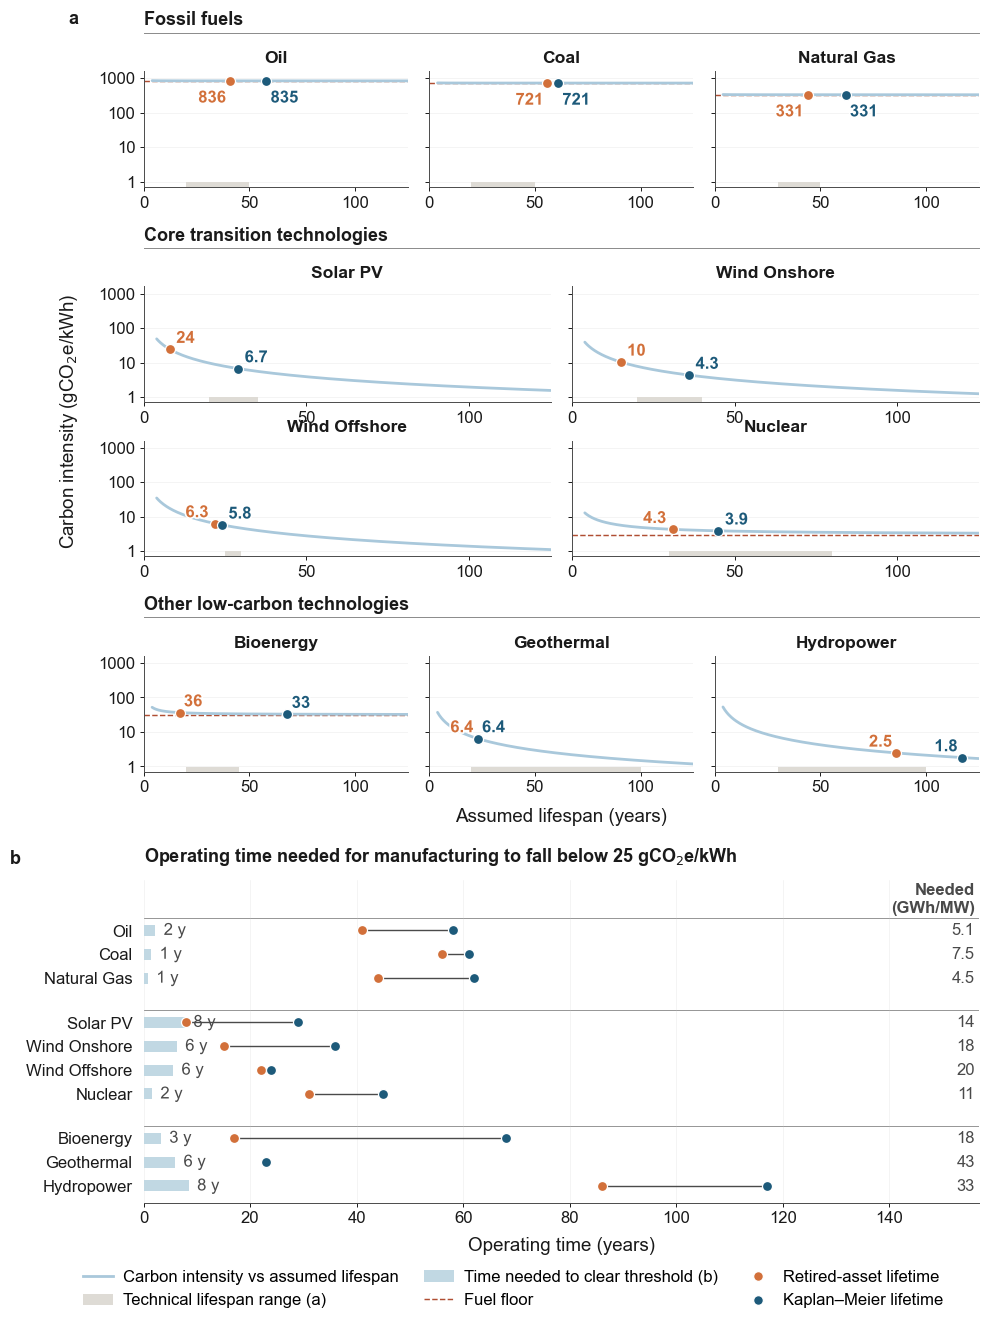

In [40]:

# ---
# Panel b - operating time needed to clear the threshold
# ---

def draw_threshold_panel(ax):
    y_positions_b = {}
    header_positions_b = {}
    line_positions_b = {}

    current_y = 0.0

    for group_name, techs in ordered_groups.items():
        if not techs:
            continue

        header_positions_b[group_name] = current_y - 0.78
        line_positions_b[group_name] = current_y - 0.50

        for tech in techs:
            y_positions_b[tech] = current_y
            current_y += 1.0

        current_y += 0.85

    order_b = [
        tech
        for group_name in ordered_groups
        for tech in ordered_groups[group_name]
    ]

    x_max = max(
        max(years_required_b[t], life_retired[t], life_km[t])
        for t in order_b
    ) * 1.34

    for group_name in ordered_groups:
        if group_name not in header_positions_b:
            continue

        ax.axhline(
            y=line_positions_b[group_name],
            color=COLOR_GROUP_LINE,
            linewidth=0.70,
            alpha=0.9,
            zorder=0,
        )

    for tech in order_b:
        y = y_positions_b[tech]
        required = years_required_b[tech]

        ax.barh(
            y,
            required,
            height=0.46,
            color=COLOR_HURDLE,
            edgecolor="none",
            zorder=1,
        )

        text_width = x_max * 0.045
        outside_x = required + x_max * 0.010

        clash = any(
            outside_x - x_max * 0.005 <= marker <= outside_x + text_width
            for marker in (life_retired[tech], life_km[tech])
        )

        inside = clash and required >= text_width * 1.15

        if inside:
            years_x, years_ha = required - x_max * 0.008, "right"
            years_colour, years_effects = COLOR_TEXT, None
        else:
            years_x, years_ha = outside_x, "left"
            years_colour, years_effects = COLOR_SECONDARY_TEXT, halo()

        ax.text(
            years_x,
            y,
            f"{required:.0f} y",
            va="center",
            ha=years_ha,
            fontsize=FONT_VALUE,
            fontweight="normal",
            color=years_colour,
            zorder=4,
            path_effects=years_effects,
        )

        generation = generation_required_mkwh_b[tech]

        ax.text(
            x_max * 0.995,
            y,
            f"{generation:.0f}" if generation >= 10 else f"{generation:.1f}",
            va="center",
            ha="right",
            fontsize=FONT_VALUE,
            fontweight="normal",
            color=COLOR_SECONDARY_TEXT,
            zorder=4,
        )

        ax.plot(
            [life_retired[tech], life_km[tech]],
            [y, y],
            color=COLOR_SECONDARY_TEXT,
            linewidth=1.0,
            zorder=4,
        )

        ax.scatter(
            life_retired[tech],
            y,
            s=52,
            color=COLOR_RETIRED,
            edgecolor="white",
            linewidth=0.9,
            zorder=5,
        )

        ax.scatter(
            life_km[tech],
            y,
            s=52,
            color=COLOR_KM,
            edgecolor="white",
            linewidth=0.9,
            zorder=6,
        )

    ax.text(
        x_max * 0.995,
        -1.30,
        "Needed\n(GWh/MW)",
        va="center",
        ha="right",
        fontsize=FONT_VALUE,
        fontweight="bold",
        color=COLOR_SECONDARY_TEXT,
        clip_on=False,
    )

    ax.set_yticks([y_positions_b[t] for t in order_b])
    ax.set_yticklabels(order_b, fontsize=FONT_TECH, color=COLOR_TEXT)

    ax.set_xlim(0, x_max)
    ax.set_ylim(max(y_positions_b.values()) + 0.70, -2.10)

    ax.set_xlabel(
        "Operating time (years)",
        fontsize=FONT_AXIS_LABEL,
        color=COLOR_TEXT,
        labelpad=8,
    )

    ax.grid(
        axis="x",
        color=COLOR_GRID,
        linewidth=0.45,
        alpha=0.30,
        zorder=0,
    )

    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color(COLOR_AXIS)
    ax.spines["bottom"].set_linewidth(0.70)

    ax.tick_params(
        axis="y",
        length=0,
        pad=8,
        colors=COLOR_TEXT,
        labelsize=FONT_TECH,
    )

    ax.tick_params(
        axis="x",
        direction="out",
        length=3.0,
        width=0.70,
        pad=3,
        colors=COLOR_TEXT,
        labelsize=FONT_TICKS,
    )


# ---
# Figure
# ---

fig = plt.figure(figsize=(9.6, 14.2))
fig.patch.set_facecolor(COLOR_BACKGROUND)

outer = fig.add_gridspec(
    2,
    1,
    height_ratios=[2.60, 1.10],
    hspace=0.2,
)

gs_a = outer[0].subgridspec(
    7,
    12,
    height_ratios=[0.2, 1.0, 0.2, 1.0, 1.0, 0.2, 1.0],
    hspace=0.5,
    wspace=0.42,
)

panel_a_axes = []
header_axes = []

# Fossil fuels: one row, three panels.
ax_header = fig.add_subplot(gs_a[0, :])
draw_group_header(ax_header, "Fossil fuels")
header_axes.append(ax_header)

for position, tech in enumerate(ordered_groups["Fossil fuels"]):
    ax = fig.add_subplot(gs_a[1, FOSSIL_SLICES[position]])
    ax.set_facecolor(COLOR_BACKGROUND)
    draw_intensity_panel(ax, tech, show_ylabel=(position == 0))
    panel_a_axes.append(ax)

# Core transition technologies: two rows by two columns.
ax_header = fig.add_subplot(gs_a[2, :])
draw_group_header(ax_header, "Core transition technologies")
header_axes.append(ax_header)

core_techs = ordered_groups["Core transition technologies"]
for position, tech in enumerate(core_techs):
    grid_row, col_slice = CORE_GRID_POSITIONS[position]
    ax = fig.add_subplot(gs_a[grid_row, col_slice])
    ax.set_facecolor(COLOR_BACKGROUND)
    draw_intensity_panel(ax, tech, show_ylabel=(position in [0, 2]))
    panel_a_axes.append(ax)

# Other low-carbon technologies: one row, three panels.
ax_header = fig.add_subplot(gs_a[5, :])
draw_group_header(ax_header, "Other low-carbon technologies")
header_axes.append(ax_header)

for position, tech in enumerate(ordered_groups["Other low-carbon technologies"]):
    ax = fig.add_subplot(gs_a[6, OTHER_SLICES[position]])
    ax.set_facecolor(COLOR_BACKGROUND)
    draw_intensity_panel(ax, tech, show_ylabel=(position == 0))
    panel_a_axes.append(ax)

# Panel b.
ax_b = fig.add_subplot(outer[1, 0])
ax_b.set_facecolor(COLOR_BACKGROUND)
draw_threshold_panel(ax_b)

ax_b.text(
    -0.16,
    1.04,
    "b",
    transform=ax_b.transAxes,
    ha="left",
    va="bottom",
    fontsize=FONT_PANEL_LABEL,
    fontweight="bold",
    color=COLOR_TEXT,
)

ax_b.text(
    0.0,
    1.04,
    (
        rf"Operating time needed for manufacturing to fall below "
        rf"{CARBON_THRESHOLD:g} gCO$_2$e/kWh"
    ),
    transform=ax_b.transAxes,
    ha="left",
    va="bottom",
    fontsize=FONT_GROUP,
    fontweight="bold",
    color=COLOR_TEXT,
)


# ---
# Legend
# ---

legend_elements = [
    Line2D(
        [0],
        [0],
        color=COLOR_CURVE,
        lw=2.0,
        label="Carbon intensity vs assumed lifespan",
    ),
    Patch(
        facecolor=COLOR_TECH_RANGE,
        edgecolor="none",
        label="Technical lifespan range (a)",
    ),
    Patch(
        facecolor=COLOR_HURDLE,
        edgecolor="none",
        label="Time needed to clear threshold (b)",
    ),
    Line2D(
        [0],
        [0],
        color=COLOR_FUEL,
        lw=1.05,
        linestyle="--",
        label="Fuel floor",
    ),
    Line2D(
        [0],
        [0],
        color="none",
        marker="o",
        markerfacecolor=COLOR_RETIRED,
        markeredgecolor="white",
        markeredgewidth=0.9,
        markersize=7,
        label="Retired-asset lifetime",
    ),
    Line2D(
        [0],
        [0],
        color="none",
        marker="o",
        markerfacecolor=COLOR_KM,
        markeredgecolor="white",
        markeredgewidth=0.9,
        markersize=7,
        label=f"Kaplan\u2013Meier lifetime",
    ),
]

fig.legend(
    handles=legend_elements,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.03),
    ncol=3,
    fontsize=FONT_LEGEND,
    columnspacing=1.5,
    handlelength=1.8,
    handletextpad=0.6,
)

fig.subplots_adjust(
    left=0.115,
    right=0.985,
    top=0.955,
    bottom=0.115,
)


# ---
# Shared labels for panel a, positioned from the rendered panel extents
# ---

fig.canvas.draw()

boxes = [ax.get_position() for ax in panel_a_axes]

a_left = min(box.x0 for box in boxes)
a_right = max(box.x1 for box in boxes)
a_bottom = min(box.y0 for box in boxes)
a_top = max(box.y1 for box in boxes)

fig.text(
    a_left - 0.078,
    (a_bottom + a_top) / 2,
    r"Carbon intensity (gCO$_2$e/kWh)",
    rotation=90,
    ha="center",
    va="center",
    fontsize=FONT_AXIS_LABEL,
    color=COLOR_TEXT,
)

fig.text(
    (a_left + a_right) / 2,
    a_bottom - 0.032,
    "Assumed lifespan (years)",
    ha="center",
    va="center",
    fontsize=FONT_AXIS_LABEL,
    color=COLOR_TEXT,
)

fig.text(
    a_left - 0.078,
    max(box.y1 for box in [ax.get_position() for ax in header_axes]),
    "a",
    ha="left",
    va="top",
    fontsize=FONT_PANEL_LABEL,
    fontweight="bold",
    color=COLOR_TEXT,
)

plt.savefig(
    "figures/main/figure-3.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/main/figure-3.pdf",
    bbox_inches="tight",
    transparent=True,
)
